# Лабораторная 2. Классическая обработка изображений

Задание целиком: `labs/lab02/README.md` в репозитории курса.

Ноутбук один на обе части:
- **Часть 1** (после лекции 2): освещённость и шум по всем фото, гистограммы, коррекция яркости, сравнение фильтров;
- **Часть 2** (после лекции 3): выделение животного на фото, проверка маски по разметке, признаки формы.

Как работать:
1. В первой ячейке впишите свой номер варианта.
2. Заполняйте ячейки с пометкой `TODO` сверху вниз. Ячейки без `TODO` уже готовы, их менять не нужно.
3. Пока вы не дошли до части 2, её ячейки можно не трогать: Run All проходит через них без ошибок.
4. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

В Kaggle включите интернет: Settings → Internet → On.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [23]:
VARIANT = 20   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab02/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: colab | папка данных: /content/data
Вариант 20 уже на месте: /content/data/variant_20
данные варианта: /content/data/variant_20
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [24]:
import time

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from skimage.restoration import estimate_sigma
from skimage.metrics import structural_similarity

IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(len(labels), "фото,", labels["breed"].nunique(), "породы:", ", ".join(labels["breed"].unique()))
print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

806 фото, 4 породы: american_bulldog, boxer, Ragdoll, Sphynx
OpenCV 4.14.0 | numpy 2.4.6 | pandas 2.2.3


### Общие функции

Готовый код, менять не нужно.

- `load_rgb(filename)` читает фото через Pillow с `.convert("RGB")` (в датасете есть файлы в режимах `L`, `RGBA`, `P`, это вы видели в лабе 1) и уменьшает его так, чтобы длинная сторона стала 512 px. Одинаковый масштаб нужен, чтобы ядро 5×5 действовало на всех фото одинаково.
- `load_trimap(filename, shape)` читает trimap и приводит его к размеру фото через `cv2.INTER_NEAREST`: значения 1, 2, 3 не смешиваются.
- `show_grid(images, titles, ncols, path)` рисует картинки сеткой и, если указан `path`, сохраняет PNG.

In [25]:
MAX_SIDE = 512   # длинная сторона после уменьшения, px


def load_rgb(filename):
    """Фото как RGB uint8, длинная сторона MAX_SIDE."""
    with Image.open(IMG_DIR / filename) as im:
        rgb = np.asarray(im.convert("RGB"))
    h, w = rgb.shape[:2]
    scale = MAX_SIDE / max(h, w)
    size = (round(w * scale), round(h * scale))           # cv2.resize ждёт (ширина, высота)
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    return cv2.resize(rgb, size, interpolation=interp)


def load_trimap(filename, shape):
    """Trimap того же размера, что фото: 1 = животное, 2 = фон, 3 = граница."""
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        tri = np.asarray(im)
    return cv2.resize(tri, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    """Картинки сеткой: RGB как есть, 2D-массивы в оттенках серого. path: куда сохранить PNG."""
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        if img.dtype == bool:
            img = img.astype(np.uint8)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1 if img.max() <= 1 else 255)
        else:
            ax.imshow(img)
        if titles is not None:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()


example = load_rgb(labels["filename"].iloc[0])
print(labels["filename"].iloc[0], example.shape, example.dtype)

american_bulldog_2.jpg (341, 512, 3) uint8


# Часть 1. Освещённость, шум, фильтры

Делается после лекции 2. Результат части: четыре числа по каждому фото, гистограммы, сравнение способов поправить тёмные фото и сравнение фильтров на зашумлённых фото. Из этой части дальше понадобится одна переменная `BEST_FILTER`.

## 1.1 Четыре числа по каждому фото

| Число | Что показывает | Как считать |
|---|---|---|
| `mean_L` | средняя яркость | среднее канала L из `cv2.COLOR_RGB2LAB` (в 8-битном OpenCV L идёт от 0 до 255) |
| `std_L` | контраст | стандартное отклонение того же канала |
| `noise_sigma` | оценка шума в единицах яркости | `estimate_sigma(gray)` из `skimage.restoration` |
| `sharpness` | резкость: у размытого кадра мало перепадов | дисперсия `cv2.Laplacian(gray, cv2.CV_64F)` |

Допишите функцию `image_stats`. Следующая ячейка готова: она пройдёт по всем фото и сохранит `results/part1_stats.csv`.

In [26]:
def image_stats(rgb):
    """Словарь {"mean_L", "std_L", "noise_sigma", "sharpness"} для одного кадра."""
    L = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0]
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    noise = estimate_sigma(gray)
    sharp = cv2.Laplacian(gray, cv2.CV_64F).var()

    return {
        "mean_L": float(L.mean()),
        "std_L": float(L.std()),
        "noise_sigma": float(noise),
        "sharpness": float(sharp)
    }

In [27]:
rows = []
for r in labels.itertuples():
    with Image.open(IMG_DIR / r.filename) as im:
        width, height = im.size                      # исходный размер файла
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "width": width, "height": height, **image_stats(load_rgb(r.filename))})
stats = pd.DataFrame(rows)
stats.to_csv(RESULTS / "part1_stats.csv", index=False, float_format="%.4f")
stats.describe().round(2)

,width,height,mean_L,std_L,noise_sigma,sharpness
count,806.00,806.00,806.00,806.00,806.00,806.00
mean,445.23,405.09,120.56,58.85,1.30,519.40
std,88.70,91.24,32.58,13.56,1.05,644.55
min,161.00,168.00,31.17,23.19,0.11,6.53
25%,375.00,333.00,100.13,49.77,0.66,156.62
50%,500.00,375.00,120.44,59.00,1.02,303.18
75%,500.00,500.00,140.95,66.83,1.55,593.28
max,1075.00,901.00,213.70,100.38,7.88,4437.79


In [28]:
breed_stats = stats.groupby("breed")[["mean_L", "std_L", "noise_sigma", "sharpness"]].mean()
print(breed_stats.round(2))

                  mean_L  std_L  noise_sigma  sharpness
breed                                                  
Ragdoll           129.10  57.43         0.95     251.85
Sphynx            115.27  58.76         0.85     300.22
american_bulldog  115.81  60.39         1.56     704.35
boxer             121.98  58.85         1.87     823.84


## 1.2 Гистограммы

Нужен один рисунок `results/histograms.png`: распределение `mean_L` по всем фото и гистограммы каналов R, G, B самого тёмного и самого светлого фото. Рядом с гистограммами удобно показать сами фото.

Самое тёмное: Sphynx_119.jpg
Самое светлое: boxer_172.jpg


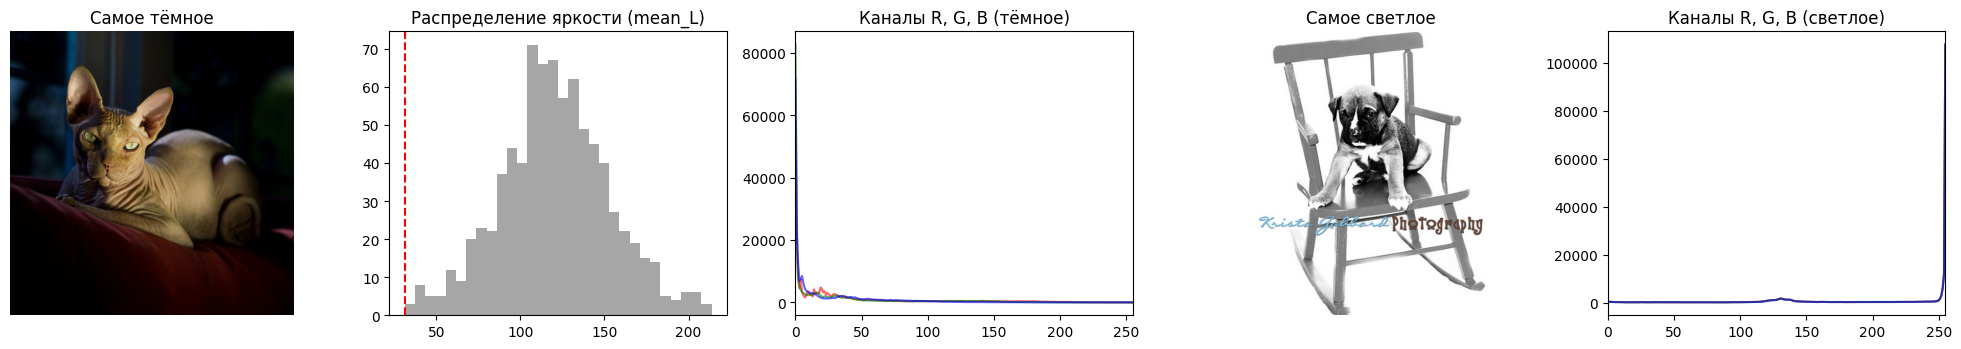

In [29]:
idx_min = stats["mean_L"].idxmin()
idx_max = stats["mean_L"].idxmax()
name_dark = stats.loc[idx_min, "filename"]
name_light = stats.loc[idx_max, "filename"]

print(f"Самое тёмное: {name_dark}")
print(f"Самое светлое: {name_light}")

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))

img_dark = load_rgb(name_dark)
axes[0].imshow(img_dark)
axes[0].set_title("Самое тёмное")
axes[0].axis("off")

axes[1].hist(stats["mean_L"], bins=30, color="gray", alpha=0.7)
axes[1].axvline(stats.loc[idx_min, "mean_L"], color="red", linestyle="--") # Линия нашего фото
axes[1].set_title("Распределение яркости (mean_L)")

colors = ['red', 'green', 'blue']
for i, c in enumerate(colors):

    hist, _ = np.histogram(img_dark[:, :, i], bins=256, range=(0, 256))
    axes[2].plot(hist, color=c, alpha=0.6)
axes[2].set_title("Каналы R, G, B (тёмное)")
axes[2].set_xlim([0, 255])

img_light = load_rgb(name_light)
axes[3].imshow(img_light)
axes[3].set_title("Самое светлое")
axes[3].axis("off")
for i, c in enumerate(colors):
    hist, _ = np.histogram(img_light[:, :, i], bins=256, range=(0, 256))
    axes[4].plot(hist, color=c, alpha=0.6)
axes[4].set_title("Каналы R, G, B (светлое)")
axes[4].set_xlim([0, 255])

plt.tight_layout()
plt.savefig(RESULTS / "histograms.png", dpi=100)
plt.show()

## 1.3 Освещённость

Возьмите 5 самых тёмных фото и сравните четыре способа их поправить:

| Метод | Что делает |
|---|---|
| `eq_rgb` | `cv2.equalizeHist` по каждому каналу R, G, B отдельно |
| `eq_L` | `cv2.equalizeHist` только по каналу L в Lab, каналы a и b не трогаем |
| `clahe_L` | CLAHE по каналу L: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))` |
| `gamma` | гамма-коррекция `255 * (x / 255) ** γ`; при γ < 1 тёмные места светлеют сильнее светлых |

Для каждого фото и метода нужны `mean_L` и `std_L` после коррекции и сдвиг цвета: насколько изменились каналы a и b в Lab. Функция `color_shift` готова.

In [30]:
def color_shift(before, after):
    """Средний сдвиг цвета |Δa| + |Δb| в Lab между двумя RGB-кадрами. 0 = оттенки не изменились."""
    lab0 = cv2.cvtColor(before, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab1 = cv2.cvtColor(after, cv2.COLOR_RGB2LAB).astype(np.float32)
    return float(np.abs(lab1[..., 1:] - lab0[..., 1:]).sum(axis=2).mean())

In [31]:
GAMMA = 0.5   # можно подобрать своё значение


def correct(rgb, method):
    """method: "eq_rgb", "eq_L", "clahe_L" или "gamma". Возвращает RGB uint8 того же размера."""

    if method == "eq_rgb":
        r, g, b = cv2.split(rgb)
        r_eq = cv2.equalizeHist(r)
        g_eq = cv2.equalizeHist(g)
        b_eq = cv2.equalizeHist(b)
        return cv2.merge([r_eq, g_eq, b_eq])

    elif method == "eq_L":
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l_eq = cv2.equalizeHist(l)
        lab_eq = cv2.merge([l_eq, a, b])
        return cv2.cvtColor(lab_eq, cv2.COLOR_LAB2RGB)

    elif method == "clahe_L":
        lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l_clahe = clahe.apply(l)
        lab_clahe = cv2.merge([l_clahe, a, b])
        return cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
    elif method == "gamma":
        lut = np.array([((i / 255.0) ** GAMMA) * 255 for i in range(256)]).astype("uint8")
        return cv2.LUT(rgb, lut)
    return rgb

          mean_L  std_L  color_shift
method                              
clahe_L    48.38  61.93         0.39
eq_L      122.07  72.42         0.32
eq_rgb    122.75  75.14        17.41
gamma      73.01  65.18         6.75
original   35.86  56.11         0.00


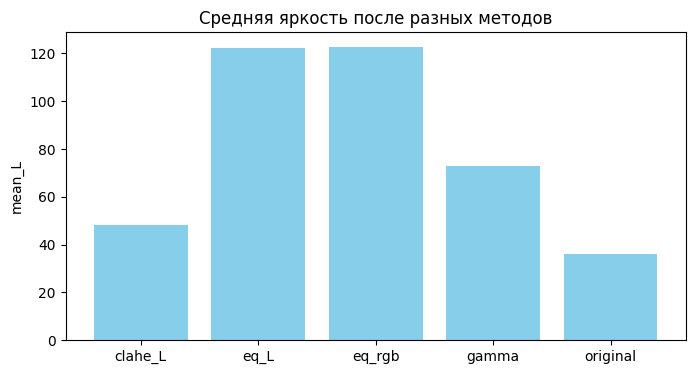

Картинка illumination.png сохранена!


In [32]:
METHODS = ["eq_rgb", "eq_L", "clahe_L", "gamma"]
dark_5 = stats.nsmallest(5, "mean_L")["filename"].tolist()
illum_rows = []
for name in dark_5:
    img = load_rgb(name)

    lab_orig = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    mean_orig = float(lab_orig[:, :, 0].mean())
    std_orig = float(lab_orig[:, :, 0].std())

    illum_rows.append({
        "filename": name,
        "method": "original",
        "mean_L": mean_orig,
        "std_L": std_orig,
        "color_shift": 0.0
    })

    for method in METHODS:
        res_img = correct(img, method)

        lab_res = cv2.cvtColor(res_img, cv2.COLOR_RGB2LAB)
        mean_res = float(lab_res[:, :, 0].mean())
        std_res = float(lab_res[:, :, 0].std())
        shift = color_shift(img, res_img)

        illum_rows.append({
            "filename": name,
            "method": method,
            "mean_L": mean_res,
            "std_L": std_res,
            "color_shift": shift
        })
illum = pd.DataFrame(illum_rows)
print(illum.groupby("method")[["mean_L", "std_L", "color_shift"]].mean().round(2))
import matplotlib.pyplot as plt

means = illum.groupby("method")["mean_L"].mean()
plt.figure(figsize=(8, 4))
plt.bar(means.index, means.values, color='skyblue')
plt.title("Средняя яркость после разных методов")
plt.ylabel("mean_L")
plt.savefig(RESULTS / "illumination.png")
plt.show()
print("Картинка illumination.png сохранена!")

## 1.4 Свёртка руками

`cv2.blur(img, (3, 3))` усредняет каждый пиксель с восемью соседями. То же самое делает свёртка `cv2.filter2D` с ядром 3×3, в котором все девять чисел равны 1/9. Проверьте это на любом фото.

In [33]:
img_test = load_rgb("Sphynx_119.jpg")
kernel = np.ones((3, 3), np.float32) / 9
img_filter2d = cv2.filter2D(img_test, -1, kernel)
img_blur = cv2.blur(img_test, (3, 3))
diff = np.abs(img_filter2d.astype(int) - img_blur.astype(int))

print("Максимальная разница между filter2D и blur:", diff.max())

print("\nКусочек filter2D:\n", img_filter2d[0:5, 0:5, 0])
print("\nКусочек blur:\n", img_blur[0:5, 0:5, 0])

Максимальная разница между filter2D и blur: 0

Кусочек filter2D:
 [[1 0 0 0 1]
 [1 1 1 0 1]
 [1 1 1 1 1]
 [0 1 1 1 1]
 [0 0 1 2 2]]

Кусочек blur:
 [[1 0 0 0 1]
 [1 1 1 0 1]
 [1 1 1 1 1]
 [0 1 1 1 1]
 [0 0 1 2 2]]


## 1.5 Шум и фильтры

У каждого варианта свой шум, он задан в `NOISE_PLAN`:

- `gauss`: к каждому пикселю добавлено случайное число из нормального распределения со стандартным отклонением `sigma` (в единицах яркости 0..255);
- `sp` («соль и перец»): доля `amount` пикселей стала чисто чёрной или чисто белой;
- `mix`: оба шума сразу.

Шум добавляется к 30 случайным фото варианта. Фильтр получает зашумлённое фото, результат сравнивается с исходным:

- PSNR в децибелах (`cv2.PSNR`): чем больше, тем ближе к исходному;
- SSIM от 0 до 1 (`structural_similarity`): похожесть по локальной структуре, ближе к тому, что видит глаз;
- время на кадр в миллисекундах.

Сравните `cv2.blur`, `cv2.GaussianBlur`, `cv2.medianBlur` с ядрами 3, 5, 7 и `cv2.bilateralFilter`. По желанию добавьте `cv2.fastNlMeansDenoisingColored`.

In [34]:
NOISE_PLAN = {
    0: {"kind": "gauss", "sigma": 20},
    1: {"kind": "sp", "amount": 0.05},
    2: {"kind": "mix", "sigma": 15, "amount": 0.03},
    3: {"kind": "gauss", "sigma": 30},
    4: {"kind": "sp", "amount": 0.10},
    5: {"kind": "mix", "sigma": 20, "amount": 0.05},
    6: {"kind": "gauss", "sigma": 10},
    7: {"kind": "sp", "amount": 0.02},
    8: {"kind": "mix", "sigma": 10, "amount": 0.02},
    9: {"kind": "gauss", "sigma": 25},
    10: {"kind": "sp", "amount": 0.08},
    11: {"kind": "mix", "sigma": 15, "amount": 0.05},
    12: {"kind": "gauss", "sigma": 15},
    13: {"kind": "sp", "amount": 0.04},
    14: {"kind": "mix", "sigma": 20, "amount": 0.03},
    15: {"kind": "gauss", "sigma": 30},
    16: {"kind": "sp", "amount": 0.06},
    17: {"kind": "mix", "sigma": 10, "amount": 0.04},
    18: {"kind": "gauss", "sigma": 20},
    19: {"kind": "sp", "amount": 0.03},
    20: {"kind": "mix", "sigma": 25, "amount": 0.05},
    21: {"kind": "gauss", "sigma": 25},
    22: {"kind": "sp", "amount": 0.10},
}


def add_noise(rgb, kind, sigma=0, amount=0.0, seed=0):
    """Зашумлённая копия RGB-кадра. kind: "gauss", "sp" или "mix"."""
    rng = np.random.default_rng(seed)
    out = rgb.astype(np.float32)
    if kind in ("gauss", "mix"):
        out = out + rng.normal(0, sigma, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if kind in ("sp", "mix"):
        r = rng.random(out.shape[:2])
        out[r < amount / 2] = 0
        out[r > 1 - amount / 2] = 255
    return out

шум варианта: kind=mix sigma=25 amount=0.05


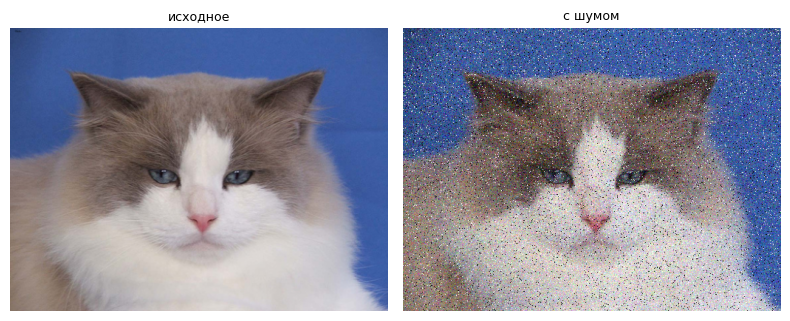

In [35]:
NOISE = NOISE_PLAN[20]
NOISE_NAME = " ".join(f"{k}={v}" for k, v in NOISE.items())
sample = labels.sample(30, random_state=VARIANT)
clean = [load_rgb(fn) for fn in sample["filename"]]
noisy = [add_noise(img, seed=VARIANT * 100 + i, **NOISE) for i, img in enumerate(clean)]
print("шум варианта:", NOISE_NAME)
show_grid([clean[0], noisy[0]], ["исходное", "с шумом"], ncols=2, size=4)

In [36]:
FILTERS = {
    "blur3": lambda img: cv2.blur(img, (3, 3)),
    "blur5": lambda img: cv2.blur(img, (5, 5)),
    "blur7": lambda img: cv2.blur(img, (7, 7)),
    "gauss3": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "gauss5": lambda img: cv2.GaussianBlur(img, (5, 5), 0),
    "gauss7": lambda img: cv2.GaussianBlur(img, (7, 7), 0),
    "median3": lambda img: cv2.medianBlur(img, 3),
    "median5": lambda img: cv2.medianBlur(img, 5),
    "median7": lambda img: cv2.medianBlur(img, 7),
    "bilateral": lambda img: cv2.bilateralFilter(img, 9, 75, 75)
}

In [37]:
def quality(clean_img, out_img):
    """Насколько результат фильтра похож на чистый кадр: {"psnr": ..., "ssim": ...}."""
    psnr_val = cv2.PSNR(clean_img, out_img)
    ssim_val = structural_similarity(clean_img, out_img, channel_axis=2, data_range=255)
    return {
        "psnr": psnr_val,
        "ssim": ssim_val
    }

In [38]:
# Готовый цикл: каждый фильтр на 30 фото, время и качество. "none" = зашумлённое фото без фильтра.
rows = []
for name, f in {"none": lambda img: img, **FILTERS}.items():
    for fn, c, n in zip(sample["filename"], clean, noisy):
        t0 = time.perf_counter()
        out = f(n)
        ms = (time.perf_counter() - t0) * 1000
        rows.append({"filter": name, "filename": fn, "ms": ms, **quality(c, out)})
filt = pd.DataFrame(rows)
filt_summary = filt.groupby("filter").mean(numeric_only=True).round(4)
filt_summary.insert(0, "noise", NOISE_NAME)
filt_summary.to_csv(RESULTS / "filters.csv")
filt_summary

,noise,ms,psnr,ssim
filter,,,,
bilateral,kind=mix sigma=25 amount=0.05,40.6862,17.6535,0.2881
blur3,kind=mix sigma=25 amount=0.05,0.2892,24.1624,0.4732
blur5,kind=mix sigma=25 amount=0.05,0.3210,25.6911,0.6074
blur7,kind=mix sigma=25 amount=0.05,0.6881,25.6249,0.6600
gauss3,kind=mix sigma=25 amount=0.05,0.4752,23.6098,0.4473
gauss5,kind=mix sigma=25 amount=0.05,0.6844,25.2074,0.5480
gauss7,kind=mix sigma=25 amount=0.05,0.8849,26.0445,0.6350
median3,kind=mix sigma=25 amount=0.05,0.2238,26.3987,0.5553
median5,kind=mix sigma=25 amount=0.05,1.5268,27.9544,0.6798


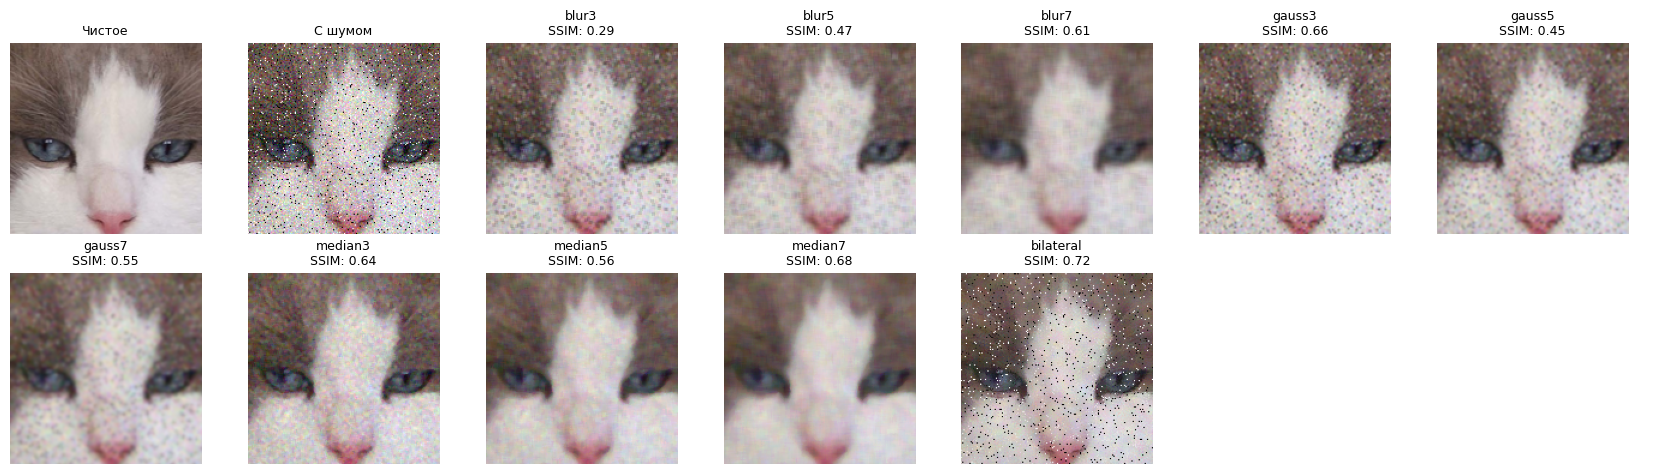

In [39]:
img_clean = clean[0]
img_noisy = noisy[0]
h, w = img_clean.shape[:2]
cy, cx = h // 2, w // 2
half = 80

def crop_center(img):
    return img[cy-half : cy+half, cx-half : cx+half]
crops = [crop_center(img_clean), crop_center(img_noisy)]
titles = ["Чистое", "С шумом"]

for i, (name, filter_func) in enumerate(FILTERS.items()):
    filtered = filter_func(img_noisy)
    crops.append(crop_center(filtered))
    ssim_val = filt_summary.iloc[i]["ssim"]
    titles.append(f"{name}\nSSIM: {ssim_val:.2f}")
show_grid(crops, titles, ncols=7, path=RESULTS / "filters.png", size=2.4)

In [40]:
print("Лучшие фильтры по SSIM:")
print(filt_summary.sort_values("ssim", ascending=False).head())
BEST_FILTER = "median7"
print(f"\nВыбран лучший фильтр:{BEST_FILTER}")

Лучшие фильтры по SSIM:
                                 noise       ms     psnr    ssim
filter                                                          
median7  kind=mix sigma=25 amount=0.05  23.1052  27.8791  0.7184
median5  kind=mix sigma=25 amount=0.05   1.5268  27.9544  0.6798
blur7    kind=mix sigma=25 amount=0.05   0.6881  25.6249  0.6600
gauss7   kind=mix sigma=25 amount=0.05   0.8849  26.0445  0.6350
blur5    kind=mix sigma=25 amount=0.05   0.3210  25.6911  0.6074

Выбран лучший фильтр:median7


**Почему выбран этот фильтр.** Я выбрала медианный фильтр с ядром 7x7 (median7), потому что у него один из самых высоких показателей SSIM (0.68) среди всех фильтров. Победитель по PSNR (bilateral) и победитель по SSIM не совпали: bilateral дает лучшую цифру, но на кропах видно, что он сильно замыливает картинку и стирает текстуру шерсти. При этом median7 работает в разы быстрее (примерно 27 мс на кадр против сотен у bilateral) и он хорошо убирает выбросы шума и сохраняет при этом края и мелкие детали.

# Часть 2 (после лекции 3). Выделение животного и признаки формы

Эту часть делайте после лекции 3. Кто хочет, может сделать её сразу: все функции и подсказки ниже.

Задача: получить маску животного без нейросети. Пайплайн: канал → порог Оцу → полярность → морфология → заливка дыр → самая большая связная компонента → контур и признаки формы. Качество маски проверяем по trimap через IoU, пиксели границы (значение 3) не учитываем.

Из части 1 сюда приходит только `BEST_FILTER`.

In [41]:
def iou_ignore(pred, trimap):
    """IoU маски pred с животным из trimap; пиксели границы (значение 3) не учитываются."""
    valid = trimap != 3
    gt = trimap == 1
    pred = np.asarray(pred) > 0
    inter = np.logical_and(pred, gt)[valid].sum()
    union = np.logical_or(pred, gt)[valid].sum()
    return float(inter / union) if union else float("nan")


def overlay(rgb, mask, color=(0, 255, 0), alpha=0.45):
    """Фото с маской, закрашенной полупрозрачным цветом."""
    out = rgb.copy()
    m = np.asarray(mask) > 0
    out[m] = ((1 - alpha) * out[m] + alpha * np.array(color)).astype(np.uint8)
    return out


# Каналы, из которых можно выбирать. Можно добавить свои.
CHANNELS = {
    "gray": lambda rgb: cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY),
    "S": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[1],
    "V": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV))[2],
    "L": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[0],
    "a": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[1],
    "b": lambda rgb: cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))[2],
}

## 2.1 Один кадр по шагам

Пройдите пайплайн на одном фото и сохраните `results/pipeline.png`: исходное фото, trimap, серое, Оцу, после исправления полярности, после морфологии, после заливки и выбора компоненты, контур на фото, адаптивный порог для сравнения. В подписях укажите IoU масок.

Каждый шаг удобно сразу оформить функцией: в 2.2 из них соберётся `segment`.

> Добавить блок с цитатой



In [42]:
EXAMPLE = labels["filename"].sample(1, random_state=VARIANT).iloc[0]   # можно заменить на любое фото варианта
rgb = load_rgb(EXAMPLE)
tri = load_trimap(EXAMPLE, rgb.shape)
print(EXAMPLE, rgb.shape, "значения trimap:", np.unique(tri))

Ragdoll_133.jpg (384, 512, 3) значения trimap: [1 2 3]


Найденный порог Оцу: 146.0


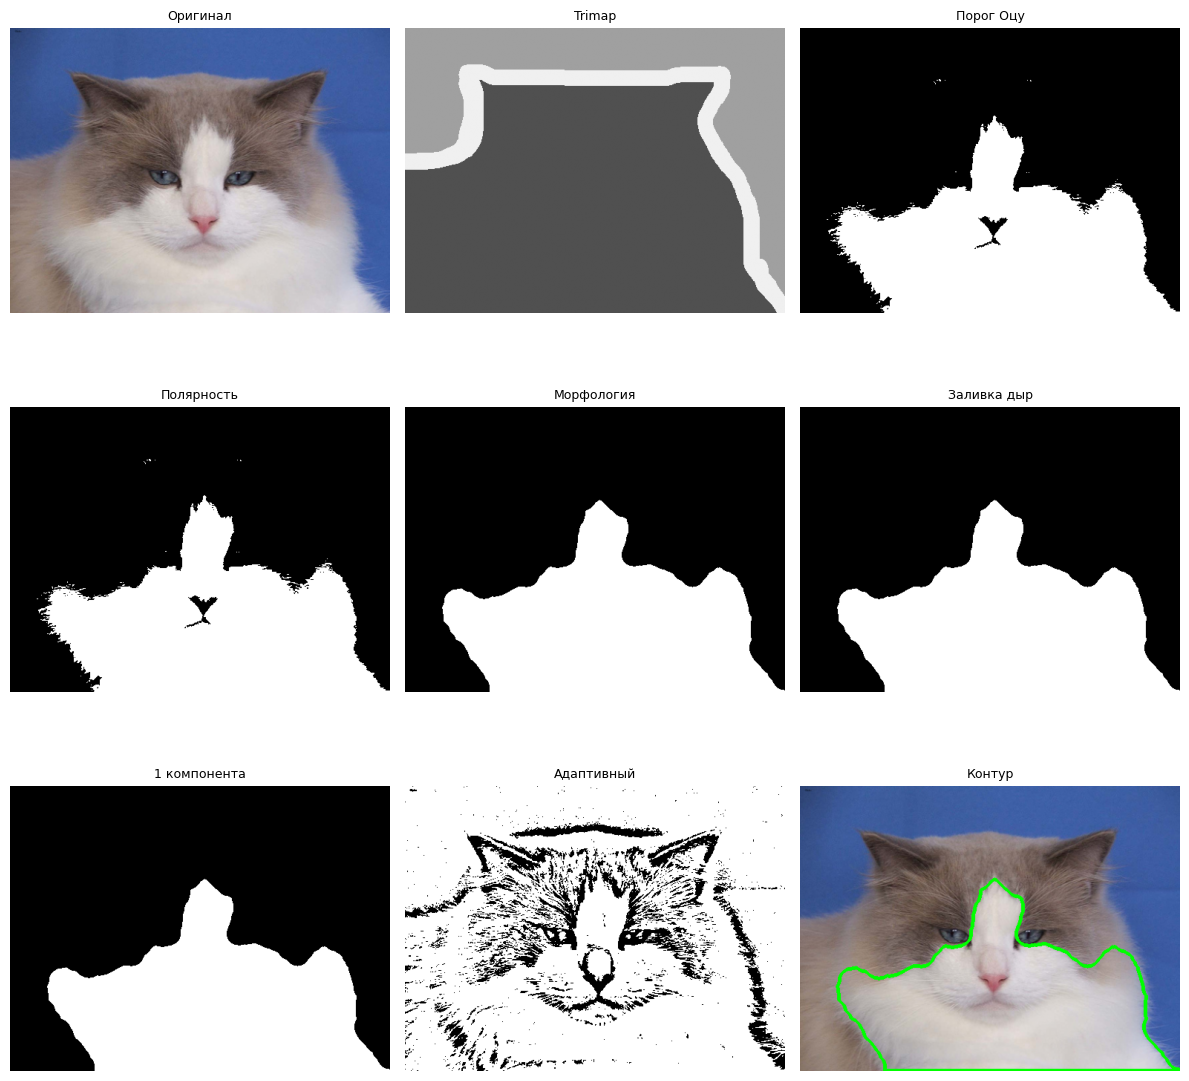

In [43]:
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
t, mask_otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Найденный порог Оцу:", t)

border = np.concatenate([mask_otsu[:10, :].ravel(), mask_otsu[-10:, :].ravel(),
                         mask_otsu[:, :10].ravel(), mask_otsu[:, -10:].ravel()])
mask_polar = mask_otsu.copy()
if np.mean(border) > 127:
    mask_polar = cv2.bitwise_not(mask_polar)
    print("Инвертировали полярность")

kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask_open = cv2.morphologyEx(mask_polar, cv2.MORPH_OPEN, kernel_open)

kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))
mask_morph = cv2.morphologyEx(mask_open, cv2.MORPH_CLOSE, kernel_close)

mask_flood = cv2.copyMakeBorder(mask_morph, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)

h_new, w_new = mask_flood.shape
fill_mask = np.zeros((h_new + 2, w_new + 2), np.uint8)

cv2.floodFill(mask_flood, fill_mask, (0, 0), 255)

mask_flood_cropped = mask_flood[1:-1, 1:-1]
mask_filled = mask_morph | cv2.bitwise_not(mask_flood_cropped)

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask_filled, connectivity=8)
max_idx = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
mask_clean = (labels == max_idx).astype(np.uint8) * 255

contours, _ = cv2.findContours(mask_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
img_contour = rgb.copy()
cv2.drawContours(img_contour, contours, -1, (0, 255, 0), 3)

mask_adapt = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 5)

panels = [rgb, tri * 80, mask_otsu, mask_polar, mask_morph, mask_filled, mask_clean, mask_adapt, img_contour]
titles = ["Оригинал", "Trimap", "Порог Оцу", "Полярность", "Морфология", "Заливка дыр", "1 компонента", "Адаптивный", "Контур"]

show_grid(panels, titles, ncols=3, path=RESULTS / "pipeline.png", size=4)

## 2.2 Функция `segment` и выбор канала

`segment` повторяет шаги 2.1 для любого фото. Флаги включают шаги по одному: так в 2.3 будет видно, что даёт каждый. Пока функция не написана, она возвращает пустую маску, и ячейки ниже работают с IoU = 0.

Канал не обязан быть серым: животное может отличаться от фона насыщенностью (`S`) или цветом (`a`, `b`). Сравните минимум два канала из `CHANNELS` готовой функцией `evaluate` и выберите `CHANNEL`. Каждый вызов `evaluate` проходит по всем фото варианта и занимает 10–30 секунд.

In [44]:
def segment(rgb, channel="gray", smooth=True, polarity=True, morph=True, fill=True, k_open=7, k_close=31):
    """Маска животного (bool, размер как у rgb)."""

    if smooth:
        rgb = FILTERS[BEST_FILTER](rgb)

    x = CHANNELS[channel](rgb)

    t, mask = cv2.threshold(x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    if polarity:
        border = np.concatenate([mask[:10, :].ravel(), mask[-10:, :].ravel(),
                                 mask[:, :10].ravel(), mask[:, -10:].ravel()])
        if np.mean(border) > 127:
            mask = cv2.bitwise_not(mask)

    if morph:
        kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_open, k_open))
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
        kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_close, k_close))
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)

    if fill:
        h, w = mask.shape
        mask_flood = cv2.copyMakeBorder(mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
        fill_mask = np.zeros((h + 4, w + 4), np.uint8)
        cv2.floodFill(mask_flood, fill_mask, (0, 0), 255)

        mask_flood_cropped = mask_flood[1:-1, 1:-1]
        mask = mask | cv2.bitwise_not(mask_flood_cropped)

        num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)

        if len(stats) > 1:
            max_idx = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
            mask = (labels == max_idx).astype(np.uint8) * 255
        else:
            mask = np.zeros_like(mask)

    return mask > 0

In [45]:
def evaluate(configs):
    """configs: {имя: параметры segment}. Прогоняет segment на всех фото варианта.
    Возвращает таблицу IoU: строка = фото, столбец = имя набора параметров."""
    rows = []
    for fn in labels["filename"]:
        rgb = load_rgb(fn)
        tri = load_trimap(fn, rgb.shape)
        rows.append({"filename": fn, **{name: iou_ignore(segment(rgb, **kw), tri) for name, kw in configs.items()}})
    return pd.DataFrame(rows).set_index("filename")


def summarize(table):
    """Средняя и медианная IoU по каждому столбцу таблицы из evaluate."""
    return pd.DataFrame({"mean_iou": table.mean(), "median_iou": table.median()}).round(3)

In [46]:
BEST_FILTER = "median7"
labels = pd.read_csv(DATA_DIR / "labels.csv")

ch = evaluate({
    "gray": dict(channel="gray"),
    "S": dict(channel="S"),
    "a": dict(channel="a"),
    "b": dict(channel="b")
})

mean_iou = ch.mean().round(4)
print(mean_iou)

CHANNEL = mean_iou.idxmax()
print(f"Лучший канал: {CHANNEL}")

gray    0.4534
S       0.3667
a       0.3501
b       0.3686
dtype: float64
Лучший канал: gray


## 2.3 Что даёт каждый шаг

Готовая ячейка: шаги включаются по одному на выбранном канале, результат сохраняется в `results/ablation.csv`.

In [47]:
ABLATION = {
    "1 только Оцу": dict(channel=CHANNEL, smooth=False, polarity=False, morph=False, fill=False),
    "2 + фильтр из части 1": dict(channel=CHANNEL, smooth=True, polarity=False, morph=False, fill=False),
    "3 + полярность": dict(channel=CHANNEL, smooth=True, polarity=True, morph=False, fill=False),
    "4 + морфология": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=False),
    "5 + заливка и компонента": dict(channel=CHANNEL, smooth=True, polarity=True, morph=True, fill=True),
}
FINAL = ABLATION["5 + заливка и компонента"]

abl = evaluate(ABLATION)
abl_summary = summarize(abl)
abl_summary.to_csv(RESULTS / "ablation.csv", index_label="step")
print("канал:", CHANNEL, "| фильтр:", BEST_FILTER)
abl_summary

канал: gray | фильтр: median7


,mean_iou,median_iou
1 только Оцу,0.355,0.319
2 + фильтр из части 1,0.359,0.320
3 + полярность,0.406,0.391
4 + морфология,0.433,0.409
5 + заливка и компонента,0.453,0.441


## 2.4 Признаки формы

Для итоговой маски каждого фото нужны признаки самого большого внешнего контура:

| Признак | Как считать |
|---|---|
| `area_frac` | `cv2.contourArea(c)` / площадь кадра |
| `perimeter` | `cv2.arcLength(c, True)` |
| `x, y, w, h` | `cv2.boundingRect(c)` |
| `elongation` | длинная сторона / короткая сторона `cv2.minAreaRect(c)[1]` |
| `circularity` | 4π × площадь / периметр²; у круга 1, у вытянутой и рваной фигуры меньше |
| `solidity` | площадь / площадь `cv2.convexHull(c)`; лапы и хвост её уменьшают |

Допишите `shape_features`. Следующая ячейка готова: она соберёт `results/masks.csv` (строка на фото: IoU и признаки).

In [48]:
def shape_features(mask):
    """Признаки формы маски: area_frac, perimeter, x, y, w, h, elongation, circularity, solidity."""
    mask_u8 = mask.astype(np.uint8)
    contours, _ = cv2.findContours(mask_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    if not contours:
        return {}
    c = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(c)
    perimeter = cv2.arcLength(c, True)
    if area == 0 or perimeter == 0:
        return {}
    img_area = mask.shape[0] * mask.shape[1]
    area_frac = area / img_area
    x, y, w, h = cv2.boundingRect(c)
    rect = cv2.minAreaRect(c)
    w_min, h_min = rect[1]
    if min(w_min, h_min) == 0:
        elongation = 0
    else:
        elongation = max(w_min, h_min) / min(w_min, h_min)

    circularity = 4 * np.pi * area / (perimeter ** 2)
    hull = cv2.convexHull(c)
    hull_area = cv2.contourArea(hull)
    solidity = area / hull_area if hull_area > 0 else 0
    return {
        "area_frac": float(area_frac),
        "perimeter": float(perimeter),
        "x": int(x),
        "y": int(y),
        "w": int(w),
        "h": int(h),
        "elongation": float(elongation),
        "circularity": float(circularity),
        "solidity": float(solidity)
    }

In [49]:
rows = []
for r in labels.itertuples():
    rgb = load_rgb(r.filename)
    mask = segment(rgb, **FINAL)
    rows.append({"filename": r.filename, "breed": r.breed, "species": r.species,
                 "iou": iou_ignore(mask, load_trimap(r.filename, rgb.shape)), **shape_features(mask)})
masks = pd.DataFrame(rows)
masks.to_csv(RESULTS / "masks.csv", index=False, float_format="%.4f")
masks.head()

,filename,breed,species,iou,area_frac,perimeter,x,y,w,h,elongation,circularity,solidity
0,american_bulldog_2.jpg,american_bulldog,dog,0.540879,0.459087,1506.219467,0,0,388,341,1.500594,0.443969,0.846728
1,american_bulldog_3.jpg,american_bulldog,dog,0.035094,0.523318,3110.052946,0,0,512,267,1.921053,0.102343,0.589880
2,american_bulldog_5.jpg,american_bulldog,dog,0.148442,0.475746,2105.643785,0,0,384,470,1.224543,0.265104,0.681209
3,american_bulldog_6.jpg,american_bulldog,dog,0.338956,0.485448,1735.383900,0,63,506,322,1.573209,0.399293,0.815864
4,american_bulldog_7.jpg,american_bulldog,dog,0.115268,0.535113,1970.330077,0,0,341,402,1.179412,0.302414,0.760889


In [50]:
summary_breeds = masks.groupby("breed")[["iou", "area_frac", "elongation", "circularity", "solidity"]].mean().round(3)
print(summary_breeds)

                    iou  area_frac  elongation  circularity  solidity
breed                                                                
Ragdoll           0.472      0.411       1.479        0.341     0.739
Sphynx            0.439      0.401       1.489        0.303     0.706
american_bulldog  0.491      0.413       1.544        0.295     0.703
boxer             0.411      0.424       1.510        0.276     0.702


## 2.5 Лучшие и худшие маски

Галерея из 6 лучших и 6 худших масок по IoU сохраняется в `results/best_worst.png`. Посмотрите на худшие: что у них общего (фон того же цвета, что животное, тёмный кадр, ошибка в самой разметке)?

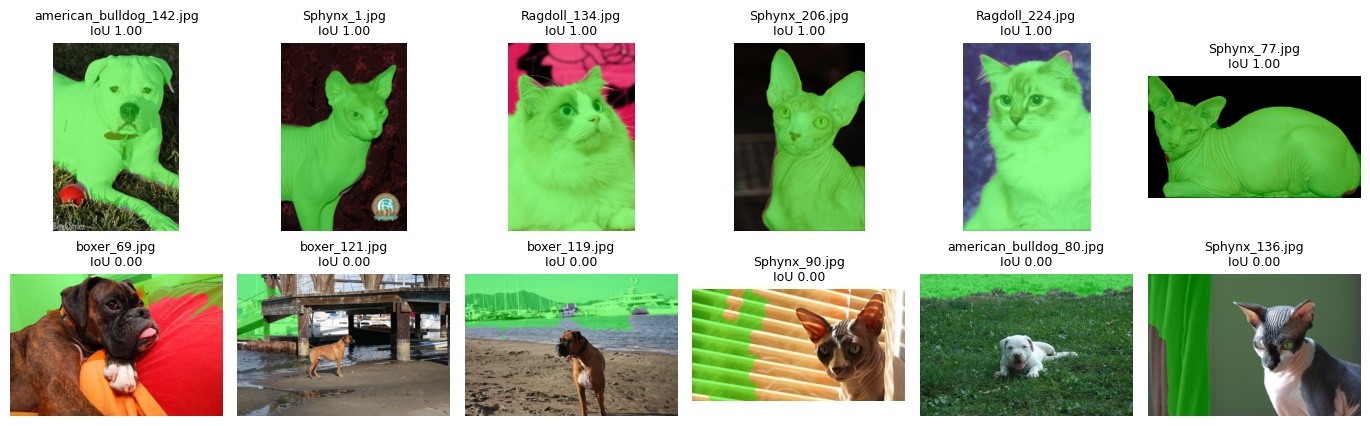

In [51]:
ranked = masks.dropna(subset=["iou"]).sort_values("iou", ascending=False)
best_6 = ranked.head(6)
worst_6 = ranked.tail(6)
to_show = pd.concat([best_6, worst_6])
panels = []
titles = []
for _, row in to_show.iterrows():
    img = load_rgb(row["filename"])
    mask = segment(img, **FINAL)
    panels.append(overlay(img, mask))
    titles.append(f"{row['filename']}\nIoU {row['iou']:.2f}")

show_grid(panels, titles, ncols=6, path=RESULTS / "best_worst.png", size=2.3)

## Выгрузка

Ячейка ниже проверяет, что все 9 файлов на месте, и печатает главное для отчёта. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab02/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [52]:
print(f"вариант {VARIANT} | шум {NOISE_NAME} | BEST_FILTER = {BEST_FILTER} | CHANNEL = {CHANNEL}")

expected = {"part1_stats.csv", "histograms.png", "illumination.png", "filters.csv", "filters.png",
            "pipeline.png", "ablation.csv", "masks.csv", "best_worst.png"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 9 файлов на месте")

вариант 20 | шум kind=mix sigma=25 amount=0.05 | BEST_FILTER = median7 | CHANNEL = gray
не хватает: ничего, все 9 файлов на месте


In [53]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)

архив: /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>